# Notebook 3 - Missing Value Handling

In this notebook I learn what missing values are, why they happen, how to detect them, and how to handle them with different techniques: dropping rows and columns, mean, median, mode and constant imputation, forward fill, backward fill, interpolation, group-based imputation, KNN imputation and iterative imputation. For every technique I write when to use it, when not to use it, its advantages and its limitations.

**Dataset:** Telco Customer Churn (7043 rows, 21 columns).

**Problem with this dataset:** After Notebook 2 only 11 values are missing (`TotalCharges`), which is too few to compare 12 techniques. So I do two things. (1) I make a **recovery experiment**: I hide some values that I know, impute them with each technique, and measure how close each technique gets to the true value. (2) I make the real decision for the 11 missing `TotalCharges` values at the end. Demo data (the time series) is always labelled.

**Rule:** `df` (raw data) is never changed.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # raw data, never modified

def fix_data_types(data):
    # the function from Notebook 2
    out = data.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce")
    out["SeniorCitizen"] = out["SeniorCitizen"].astype(bool)
    for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        out[col] = out[col].map({"Yes": True, "No": False})
    for col in ["gender", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                "Contract", "PaymentMethod", "Churn"]:
        out[col] = out[col].astype("category")
    return out

df_clean = fix_data_types(df)
print("Shape:", df_clean.shape)

Shape: (7043, 21)


## 1. Problems from Sprint 4 Related to Missing Values

| # | Problem | Why it exists | Planned fix |
|---|---|---|---|
| 1 | `isna()` shows no missing values, but `TotalCharges` has 11 blank strings | blanks are text, not `NaN` | already made visible in Notebook 2 |
| 2 | The 11 blanks all belong to customers with `tenure = 0` | these customers have not received a first bill | decide with a business reason, not only a statistic |
| 3 | I must not fill everything with the mean | the sprint rule, and a mean can give a wrong value | compare techniques before choosing |

## 2. What are Missing Values? Detecting Them and the Missing Percentage

**Concept:** A missing value is a place in the table where a value should exist but is not available. In pandas the standard marker is `NaN` (for dates `NaT`). Missing values are dangerous because many models cannot accept them, and because the way they are handled can change the result. Some missing values are hidden behind other markers like a blank space, `?`, `N/A` or `-`, and `isna()` does not see them.

**Examples:**
- Simple: a list `[10, 20, NaN, 40]` has one missing value.
- Real-world: a survey where some people skip the income question.
- Business: a customer who has not received a first bill has no `TotalCharges`.
- AI/ML: scikit-learn models like logistic regression stop with an error when the data has `NaN`.

**Implementation:** I count the missing values with `isna()`, then I look for hidden markers in the raw data, then I calculate the percentage per column.

In [4]:
markers = ["", "?", "na", "n/a", "null", "none", "-", "--", "nan", "unknown", "missing"]

report = []
for col in df.columns:
    real_nan = int(df[col].isna().sum())
    if pd.api.types.is_numeric_dtype(df[col]):
        hidden = 0
    else:
        cleaned = df[col].astype(str).str.strip().str.lower()
        hidden = int(cleaned.isin(markers).sum()) - int(df[col].isna().sum())   # astype(str) turns NaN into 'nan'
        hidden = max(hidden, 0)
    report.append((col, real_nan, hidden))

missing_report = pd.DataFrame(report, columns=["column", "isna_count", "hidden_marker_count"]).set_index("column")
missing_report["total_missing"] = missing_report.sum(axis=1)
missing_report["missing_%"] = (missing_report["total_missing"] / len(df) * 100).round(3)

print("Columns with any missing value:")
print(missing_report[missing_report["total_missing"] > 0])
print("\nTotal missing cells:", int(missing_report["total_missing"].sum()), "of", df.size,
      "(" + str(round(missing_report["total_missing"].sum() / df.size * 100, 4)) + "%)")
print("Rows with at least one missing value after Notebook 2:", int(df_clean.isna().any(axis=1).sum()))

Columns with any missing value:
              isna_count  hidden_marker_count  total_missing  missing_%
column                                                                 
TotalCharges           0                   11             11      0.156

Total missing cells: 11 of 147903 (0.0074%)
Rows with at least one missing value after Notebook 2: 11


**What the code does:**
- It goes through every column of the raw data. For each column it counts the real `NaN` values with `isna()`.
- For text columns it also converts everything to lower case without spaces and checks if the value is one of the typical missing markers (empty, `?`, `n/a`, `null`, `-`, `unknown` and so on). These are the hidden missing values.
- It adds both counts to a `total_missing` column and divides by the number of rows to get the missing percentage.
- It prints only the columns that have at least one missing value, the total share of missing cells, and the number of rows with a missing value in the cleaned data from Notebook 2.

**Why this method was used:** Only calling `isna()` would say that the dataset is complete, because the 11 blank values are stored as spaces. I need a second check for hidden markers. The percentage matters because the size of the problem decides the technique: a column with 0.15% missing and a column with 60% missing cannot be treated in the same way. I check the percentage per column and not for the whole table, because 11 missing values in one column can be a big problem for that column even if the total is tiny.

**Before:** `isna()` reports 0 missing values.

**After:** The real problem is visible: only `TotalCharges` has missing values, 11 values (about 0.16% of the rows). No other column has a hidden marker.

**Effect on ML:** The missing share is very small, so the decision is not about "how to save a lot of data". It is about "which value is correct for these 11 customers". This is why I look at the reason in the next section.

## 3. Why Missing Values Occur

**Concept:** Before I choose a technique I need to know why the value is missing. The usual reasons are: the value was not collected (a skipped question), a system or sensor error, the value does not exist yet or does not apply (a structural missing value), data was lost when joining or moving data, and people decided not to answer (for example high income).

**Examples:**
- Simple: a student did not write the age in a form.
- Real-world: a thermometer stops sending data for two hours.
- Business: a new customer has no total charges because there is no bill yet.
- AI/ML: a missing value that is created by a join with a table that has no matching row.

**Implementation:** I look at the 11 rows with a missing `TotalCharges`, and compare them with the other customers.

In [5]:
missing_rows = df_clean[df_clean["TotalCharges"].isna()]
print(missing_rows[["customerID", "tenure", "MonthlyCharges", "Contract", "Churn"]])

print("\nTenure of the rows with missing TotalCharges:", missing_rows["tenure"].unique().tolist())
print("Customers with tenure == 0 in the whole data:", int((df_clean["tenure"] == 0).sum()),
      "| of them with missing TotalCharges:", int(((df_clean["tenure"] == 0) & df_clean["TotalCharges"].isna()).sum()))

print("\nMean tenure -> missing rows:", round(missing_rows["tenure"].mean(), 1),
      "| other rows:", round(df_clean.loc[df_clean["TotalCharges"].notna(), "tenure"].mean(), 1))
print("Churn among missing rows:", missing_rows["Churn"].value_counts().to_dict())
print("Contract among missing rows:", missing_rows["Contract"].value_counts().to_dict())

      customerID  tenure  MonthlyCharges  Contract Churn
488   4472-LVYGI       0           52.55  Two year    No
753   3115-CZMZD       0           20.25  Two year    No
936   5709-LVOEQ       0           80.85  Two year    No
1082  4367-NUYAO       0           25.75  Two year    No
1340  1371-DWPAZ       0           56.05  Two year    No
3331  7644-OMVMY       0           19.85  Two year    No
3826  3213-VVOLG       0           25.35  Two year    No
4380  2520-SGTTA       0           20.00  Two year    No
5218  2923-ARZLG       0           19.70  One year    No
6670  4075-WKNIU       0           73.35  Two year    No
6754  2775-SEFEE       0           61.90  Two year    No

Tenure of the rows with missing TotalCharges: [0]
Customers with tenure == 0 in the whole data: 11 | of them with missing TotalCharges: 11

Mean tenure -> missing rows: 0.0 | other rows: 32.4
Churn among missing rows: {'No': 11, 'Yes': 0}
Contract among missing rows: {'Two year': 10, 'One year': 1, 'Month-to-month

**What the code does:**
- It selects the 11 rows where `TotalCharges` is missing and prints the columns that can explain the reason: tenure, monthly charges, contract and churn.
- It checks if there is a relation between "missing" and "tenure is 0": how many customers have tenure 0 in the whole data, and how many of them have a missing `TotalCharges`.
- It compares the mean tenure of the missing rows with the mean of the other rows.
- It shows the churn and contract values of the missing rows.

**Why this method was used:** The best way to understand a missing value is to compare the rows that miss it with the rows that do not. If the missing rows are different in some other column, the missing is not random. I look at `tenure` first because `TotalCharges` is the total amount paid over the tenure, so the two columns are connected by definition. Checking the churn and contract values shows if the missing rows are a special group that the model needs to learn from.

**Output meaning:** All 11 missing rows have `tenure = 0`, and all customers with tenure 0 are in the missing group, so the relation works in both directions. These customers are new, they have a monthly charge, and they have not paid anything yet. They also have a valid contract.

**Insight obtained:** These missing values are not a data collection error. The value does not exist yet, so it is a **structural missing value**. A statistic like the mean would invent a value that does not exist, and the correct value from the business point of view is 0.

**Effect on ML:** This is the information the model needs about brand-new customers, so the rows should be kept and filled with a correct value. I make the final decision in Section 13.

## 4. MCAR, MAR and MNAR

**Concept:** The three types describe why the value is missing, and they decide which techniques are safe.
- **MCAR (Missing Completely At Random):** the chance of being missing does not depend on any value in the data. Dropping the rows does not create bias, it only loses information.
- **MAR (Missing At Random):** the chance of being missing depends on other columns that I can see, but not on the missing value itself. It can be corrected by using the other columns (group, KNN, iterative).
- **MNAR (Missing Not At Random):** the chance of being missing depends on the missing value itself. Nothing in the data shows it, and any simple imputation is biased.

**Examples:**
- MCAR: a lab sample is dropped by accident.
- MAR: younger people skip a question more often, and age is known.
- MNAR: people with a high income do not write their income.
- AI/ML: with MNAR a "was missing" flag column can carry information for the model.

**Implementation:** The Telco data has almost no missing values, so I simulate the three types on `MonthlyCharges` (a column where I know the true values), and I compare what each type does to the data. I use only the customers with a complete `TotalCharges` (tenure above 0).

In [6]:
rng = np.random.default_rng(42)

base = df_clean[df_clean["tenure"] > 0].reset_index(drop=True)      # complete rows, ground truth is known
n = len(base)
true_mean = base["MonthlyCharges"].mean()

# MCAR: every row has the same 15% chance
mcar = rng.random(n) < 0.15

# MAR: the chance depends on another column that we can see (Contract)
p_contract = base["Contract"].map({"Month-to-month": 0.25, "One year": 0.08, "Two year": 0.02}).astype(float)
mar = rng.random(n) < p_contract.to_numpy()

# MNAR: the chance depends on the value itself (high charges are hidden more often)
p_value = np.where(base["MonthlyCharges"] > 80, 0.30, 0.05)
mnar = rng.random(n) < p_value

rows = []
for name, mask in [("MCAR", mcar), ("MAR", mar), ("MNAR", mnar)]:
    observed = base.loc[~mask, "MonthlyCharges"]
    rows.append({
        "type": name,
        "missing_%": round(mask.mean() * 100, 1),
        "true_mean": round(true_mean, 2),
        "mean_of_observed": round(observed.mean(), 2),
        "bias": round(observed.mean() - true_mean, 2),
        "tenure_gap(missing-observed)": round(base.loc[mask, "tenure"].mean() - base.loc[~mask, "tenure"].mean(), 1),
        "month-to-month share after dropping_%": round((base.loc[~mask, "Contract"] == "Month-to-month").mean() * 100, 1),
    })
print("Month-to-month share in the full data (%):", round((base["Contract"] == "Month-to-month").mean() * 100, 1))
pd.DataFrame(rows).set_index("type")

Month-to-month share in the full data (%): 55.1


,missing_%,true_mean,mean_of_observed,bias,tenure_gap(missing-observed),month-to-month share after dropping_%
type,,,,,,
MCAR,15.1,64.8,64.88,0.08,-1.0,55.0
MAR,15.8,64.8,64.69,-0.11,-12.0,49.3
MNAR,14.1,64.8,61.66,-3.14,6.7,55.3


**What the code does:**
- It takes the customers with a complete `TotalCharges`, so the true value of every cell is known.
- It creates three different masks of about 15% missing values for `MonthlyCharges`. In MCAR every row has the same probability. In MAR the probability depends on the contract (month-to-month customers miss more often). In MNAR the probability depends on the value itself (a charge above 80 has a higher chance to be missing).
- For each type it compares the mean of the observed values with the true mean (the bias), the difference in tenure between missing and observed rows, and the share of month-to-month customers that are left if I drop the missing rows.

**Why this method was used:** On real data I can never know the true mechanism, because the missing values are, by definition, not there. A simulation is the only way to see the effect of each type with a known answer. I chose Contract as the helper for MAR and the value itself for MNAR, because these are realistic: contract is connected with customer behaviour, and expensive plans are the ones people may hide.

**Output meaning:** In MCAR the mean of the observed values is almost the true mean, and the missing and observed rows look the same. In MAR the missing rows are different from the others (look at the tenure gap, which should be clearly away from 0 on the real data), and the share of month-to-month customers changes after dropping the rows. The bias of the mean can be small for this column, but the population is no longer the same. In MNAR the mean of the observed values is clearly lower than the true mean, because the high values disappeared.

**Insight obtained:** The same 15% missing can be harmless (MCAR) or can change the population (MAR) or hide the big values (MNAR). The percentage alone does not tell which one I have. MAR can be detected by comparing the missing rows with the others, MNAR cannot be seen from the data and needs business knowledge.

**The real `TotalCharges` case:** The missing rows are fully explained by another observed column (`tenure = 0`), so this is MAR, and more precisely a structural missing value. It is not MCAR, so dropping the rows would remove a group (all new customers) from the data.

**Effect on ML:** The mechanism decides the technique. MCAR allows simple methods, MAR needs methods that use the other columns, and MNAR needs business knowledge or a missing indicator column.

## 5. Dropping Rows

**Concept:** `dropna()` removes every row that has a missing value. It is the simplest method, because no value is invented.

- **When to use:** the missing share is very small (below about 5%) and the missing is MCAR, or the row is useless (for example the target is missing).
- **When not to use:** the missing is MAR or MNAR, many rows are affected, or the dataset is small.
- **Advantages:** simple, no invented values, no assumption about the values.
- **Limitations:** loses information, and can bias the data and change the class balance when the missing is not random.

**Examples:**
- Simple: remove the one row with an empty age.
- Real-world: delete survey forms that are almost empty.
- Business: remove records where the target (churn) is not known.
- AI/ML: the model sees a different population than the real one if the dropped rows are a special group.

**Implementation:** I drop the rows on the real data and on the simulated MAR data, and compare the data before and after.

In [7]:
# real data
dropped = df_clean.dropna()
print("REAL DATA")
print("  rows before:", len(df_clean), "| after dropna():", len(dropped), "| lost:", len(df_clean) - len(dropped))
print("  customers with tenure 0 before:", int((df_clean["tenure"] == 0).sum()), "| after:", int((dropped["tenure"] == 0).sum()))
print("  churn rate before:", round((df_clean["Churn"] == "Yes").mean() * 100, 2), "% | after:", round((dropped["Churn"] == "Yes").mean() * 100, 2), "%")

# simulated MAR (from Section 4): what dropping does to the population
kept = base[~mar]
print("\nSIMULATED MAR (15% missing)")
print("  rows before:", len(base), "| after:", len(kept))
for contract in ["Month-to-month", "One year", "Two year"]:
    before = (base["Contract"] == contract).mean() * 100
    after = (kept["Contract"] == contract).mean() * 100
    print("  share of", contract.ljust(15), "before:", round(before, 1), "% | after:", round(after, 1), "%")
print("  churn rate before:", round((base["Churn"] == "Yes").mean() * 100, 2), "% | after:", round((kept["Churn"] == "Yes").mean() * 100, 2), "%")

REAL DATA
  rows before: 7043 | after dropna(): 7032 | lost: 11
  customers with tenure 0 before: 11 | after: 0
  churn rate before: 26.54 % | after: 26.58 %

SIMULATED MAR (15% missing)
  rows before: 7032 | after: 5922
  share of Month-to-month  before: 55.1 % | after: 49.3 %
  share of One year        before: 20.9 % | after: 22.8 %
  share of Two year        before: 24.0 % | after: 28.0 %
  churn rate before: 26.58 % | after: 24.45 %


**What the code does:**
- On the real data it calls `dropna()` and prints how many rows are lost, how many customers with tenure 0 remain, and how the churn rate changes.
- On the simulated MAR data it removes the rows that are missing and compares the share of every contract type and the churn rate before and after.

**Why this method was used:** The question about dropping is not "how many rows do I lose", but "which rows do I lose". So I compare the composition of the data (tenure, contract, churn) before and after. I use the simulation as well, because on the real data 11 rows cannot show the bias, but a MAR example shows it clearly.

**Output meaning:** On the real data, only 11 rows are lost (0.16%), but they are exactly the customers with tenure 0, so the group disappears completely from the dataset. In the MAR simulation the share of month-to-month customers falls after dropping, and the churn rate changes, because month-to-month customers are the ones that leave most often.

**Why not appropriate here:** A tiny percentage looks harmless, but the lost rows are one special group. Dropping would give a model that has never seen a new customer, and in production the first thing it would meet is new customers.

**Effect on ML:** Dropping rows can change the class balance and the population without any warning. I drop rows only when the missing is MCAR and small, or when the row has no usable information.

## 6. Dropping Columns

**Concept:** `drop(columns=...)` removes a whole column that has too many missing values.

- **When to use:** the missing share is very high (a common rule of thumb is above 50% to 60%), and the column is not important or cannot be filled in a reliable way.
- **When not to use:** the column is important for the problem, or the missing value itself has a meaning (for example "no previous loan").
- **Advantages:** removes noise, and avoids imputing a column that is mostly invented.
- **Limitations:** the information in the observed values is lost, and the threshold is a rule of thumb and not a law.

**Examples:**
- Simple: a column that is empty in 90% of the rows.
- Real-world: an optional "second phone number" field.
- Business: a referral code that only a few customers have.
- AI/ML: imputing 70% of a column means that the model learns mostly from invented values.

**Implementation:** A function drops the columns above a threshold. In Telco no column is above any threshold, so I also test it on a demo column that I add on a copy.

In [8]:
def drop_sparse_columns(data, threshold=50):
    missing_pct = data.isna().mean() * 100
    to_drop = missing_pct[missing_pct > threshold].index.tolist()
    return data.drop(columns=to_drop), to_drop, missing_pct

# real data
_, dropped_cols, pct = drop_sparse_columns(df_clean)
print("REAL DATA: highest missing % of a column:", round(pct.max(), 2), "(" + pct.idxmax() + ") | columns dropped:", dropped_cols)

# DEMO: a made-up column with 70% missing values on a copy
demo = df_clean.copy()
demo["referral_code"] = "R"
demo.loc[rng.random(len(demo)) < 0.70, "referral_code"] = np.nan

demo_after, dropped_cols, pct = drop_sparse_columns(demo, threshold=50)
print("\nDEMO: referral_code missing %:", round(pct["referral_code"], 1))
print("columns before:", demo.shape[1], "| after:", demo_after.shape[1], "| dropped:", dropped_cols)

REAL DATA: highest missing % of a column: 0.16 (TotalCharges) | columns dropped: []

DEMO: referral_code missing %: 69.5
columns before: 22 | after: 21 | dropped: ['referral_code']


**What the code does:**
- The function `drop_sparse_columns` calculates the missing percentage of every column with `isna().mean()`, selects the columns above the threshold (50% by default), and returns the data without them, the list of dropped columns and the percentages.
- It is run on the real data, and on a demo copy where I added a made-up column `referral_code` with about 70% missing values.

**Why this method was used:** A function with a threshold parameter makes the rule visible and repeatable, and I can use it again in the final workflow (Notebook 16). A separate `drop(columns=...)` line with a name typed by hand would hide the reason. I use a demo column because the real data has no sparse column. The function returns the list of dropped columns, so the decision is always documented.

**Output meaning:** On the real data the highest missing percentage is about 0.16%, so nothing is dropped. In the demo the new column is above 50%, so it is dropped and the number of columns falls by one.

**Effect on ML:** For Telco this technique is not needed. I keep the function as a protection for the final pipeline, because new data can have a column that is mostly empty.

## 7. Simple Imputation: Mean, Median, Mode and Constant

**Concept:** Imputation means filling the missing value with a replacement value. The simple methods use one number for all missing cells in a column. They are quick, but they ignore all other columns.

To compare techniques fairly, I use the **recovery experiment**: I take `TotalCharges` of customers with tenure above 0, hide 15% of the values at random (MCAR), impute them with each technique, and measure how far the imputed values are from the truth. The measures are:
- **RMSE:** the average size of the error at the hidden positions (lower is better).
- **std:** the spread of the column after imputation, to compare with the true spread.
- **corr_with_tenure:** the correlation between the column and `tenure`, to see if the relationship between columns survives.

In [9]:
rng2 = np.random.default_rng(7)

truth = base["TotalCharges"].copy()                  # the real values
mask = rng2.random(n) < 0.15                         # 15% hidden at random (MCAR)
observed = truth.copy()
observed[mask] = np.nan

exp = base[["tenure", "MonthlyCharges", "Contract", "InternetService"]].copy()
exp["TotalCharges"] = observed

results = {}
def evaluate(name, imputed):
    rmse = np.sqrt(((imputed[mask] - truth[mask]) ** 2).mean())
    results[name] = {"RMSE": round(rmse, 1), "std": round(imputed.std(), 1),
                     "corr_with_tenure": round(imputed.corr(base["tenure"]), 3)}

print("Hidden values:", int(mask.sum()), "of", n)
print("TRUE values  -> mean:", round(truth.mean(), 1), "| std:", round(truth.std(), 1), "| corr with tenure:", round(truth.corr(base["tenure"]), 3))

Hidden values: 1031 of 7032
TRUE values  -> mean: 2283.3 | std: 2266.8 | corr with tenure: 0.826


**What the code does:**
- It takes `base` (customers with a complete `TotalCharges`), keeps the real values in `truth`, and hides 15% of them randomly in `observed`.
- It builds a table `exp` with the columns that I can use for imputation (tenure, monthly charges, contract, internet service) and the column with holes.
- It defines the function `evaluate`, which takes an imputed column, calculates the RMSE only at the hidden positions, and saves RMSE, std and the correlation with tenure in a results dictionary.
- It prints the true mean, std and correlation, as the reference.

**Why this method was used:** If I only impute and look at the result, every method looks fine, because there is nothing to compare with. By hiding values that I know, I get a score for each method. I measure the error only at the hidden positions, because the other positions are not changed. I add std and the correlation because a method can have a small error and still destroy the shape of the data or the relation between columns, and that matters for a model.

**Effect on ML:** The same set of hidden values is used for every technique, so the comparison is fair. All statistics (mean, median) are calculated from the observed values only, never from the hidden ones.

### 7.1 Mean Imputation

- **When to use:** a numeric column with a roughly symmetric distribution, no outliers, a small MCAR missing share.
- **When not to use:** skewed data or outliers (the mean is pulled), large missing share, or when the relation with other columns matters.
- **Advantages:** very fast and simple, keeps the column mean.
- **Limitations:** reduces the variance, creates a spike at one value, weakens correlations.

**Examples:**
- Simple: fill a missing height with the average height.
- Real-world: a missing temperature in a stable room.
- Business: a missing monthly fee when all fees are similar.
- AI/ML: a quick baseline for a numeric feature.

In [10]:
mean_value = observed.mean()
imputed_mean = observed.fillna(mean_value)
evaluate("mean", imputed_mean)

print("Mean used for filling:", round(mean_value, 1))
print(pd.DataFrame(results).T)

Mean used for filling: 2278.0
        RMSE     std  corr_with_tenure
mean  2296.7  2089.2             0.763


**What the code does:** It calculates the mean of the observed `TotalCharges` (`mean()` skips the `NaN` automatically), fills every hole with that one number using `fillna`, and evaluates the result.

**Why this method was used:** It is the baseline that everybody knows, so every other technique can be compared with it. I show it first to see what a "simple" answer costs. `fillna(mean)` is used instead of looping, because it fills all holes at once with the same value.

**Output meaning:** The error is large, because a customer who stayed 70 months and a customer who stayed 2 months get the same value. The std of the column becomes smaller than the true std, and the correlation with tenure becomes weaker than the true correlation.

**Effect on ML:** The model sees a lot of rows with exactly the same value, which is an artificial peak. It also learns that `TotalCharges` is less connected with `tenure` than it really is.

### 7.2 Median Imputation

- **When to use:** skewed data or data with outliers, which describes `TotalCharges` (right skewed).
- **When not to use:** when the relation with other columns matters, or the missing share is large.
- **Advantages:** not affected by outliers, simple.
- **Limitations:** same problems as the mean: one value for all rows, smaller variance, weaker correlations.

**Examples:**
- Simple: fill a missing salary with the middle salary.
- Real-world: house prices, where a few mansions pull the mean up.
- Business: the typical bill of customers when a few customers pay very high bills.
- AI/ML: the default numeric strategy in many pipelines (`SimpleImputer(strategy="median")`).

In [11]:
median_value = observed.median()
imputed_median = observed.fillna(median_value)
evaluate("median", imputed_median)

print("Median used for filling:", round(median_value, 1), "| mean was:", round(mean_value, 1))
print(pd.DataFrame(results).T)

Median used for filling: 1397.6 | mean was: 2278.0
          RMSE     std  corr_with_tenure
mean    2296.7  2089.2             0.763
median  2472.6  2112.3             0.754


**What the code does:** It calculates the median of the observed values, fills the holes with it, and evaluates the result in the same way as for the mean.

**Why this method was used:** `TotalCharges` is right skewed (Sprint 4), so a few very high values pull the mean above the typical customer. The median is the middle value and does not move because of these few values. That is the reason I prefer it to the mean for this column. I still compare both, because the median is not always better.

**Output meaning:** The median is smaller than the mean, which is a sign of skewness. The errors of the mean and the median are similar and both are large, because both give one value to every row. The median keeps the typical level and does not copy the pull of the large values.

**Effect on ML:** The median is a safer default than the mean for skewed columns, but it has the same weaknesses: the spread becomes smaller and the relation with tenure becomes weaker.

### 7.3 Mode Imputation

- **When to use:** categorical columns, with one clearly most frequent label and a small missing share.
- **When not to use:** the categories have similar frequencies, or the missing share is large, or the column is numeric and continuous.
- **Advantages:** works for text labels, simple.
- **Limitations:** makes the most common label even more common, and can hide a minority group.

**Examples:**
- Simple: fill a missing "country" with the most common country.
- Real-world: a missing "payment type" with the most used one.
- Business: a missing internet service type of a customer.
- AI/ML: the default categorical strategy (`SimpleImputer(strategy="most_frequent")`).

In [12]:
cat_true = base["InternetService"].astype(str)
cat_mask = rng2.random(n) < 0.15
cat_observed = cat_true.copy()
cat_observed[cat_mask] = np.nan

mode_value = cat_observed.mode()[0]
cat_mode = cat_observed.fillna(mode_value)

accuracy = (cat_mode[cat_mask] == cat_true[cat_mask]).mean() * 100
print("Mode used:", mode_value)
print("Share of hidden values that were filled correctly:", round(accuracy, 1), "%")

distribution = pd.DataFrame({
    "true_%": cat_true.value_counts(normalize=True) * 100,
    "after_mode_%": cat_mode.value_counts(normalize=True) * 100,
}).round(1)
print()
print(distribution)

Mode used: Fiber optic
Share of hidden values that were filled correctly: 45.7 %

                 true_%  after_mode_%
InternetService                      
Fiber optic        44.0          52.3
DSL                34.4          29.1
No                 21.6          18.6


**What the code does:**
- It hides 15% of the values of a categorical column (`InternetService`) in the same way as before.
- It finds the most frequent label with `mode()`, fills the holes with it, and checks how many of the hidden values were filled correctly.
- It compares the share of every label before and after the imputation.

**Why this method was used:** The mean and the median do not exist for text labels, so the mode is the standard choice. I measure the accuracy of the filled values instead of RMSE, because for labels the error is "right or wrong". I compare the distribution because the main risk of the mode is that it changes the balance between labels.

**Output meaning:** The accuracy is only about as high as the share of the most common label, so about half of the filled labels are wrong or even less. The most frequent label gets a larger share than in the true data, and the other labels get smaller.

**Effect on ML:** The imputed data over-represents the majority label. With a small missing share this is not a big problem, but with a large share the model learns a distorted category distribution.

### 7.4 Constant Value Imputation

- **When to use:** the missing value has a meaning ("not applicable", "none", or a business rule such as 0 for "no bill yet"), or I want a "Missing" label for a category.
- **When not to use:** the constant has no real meaning in a numeric column (it will look like a real value).
- **Advantages:** simple, can carry the meaning of the missing, and does not depend on the data statistics.
- **Limitations:** a wrong constant creates a fake value, and for numeric columns it distorts the distribution.

**Examples:**
- Simple: fill a missing "number of children" with 0 if the form was left empty on purpose.
- Real-world: fill the empty "middle name" with "none".
- Business: `TotalCharges` = 0 for a customer who has not been billed.
- AI/ML: a "Missing" label lets the encoder make its own column for the missing group.

In [13]:
# numeric: constant 0 for TotalCharges (random missing, so this is the wrong use here)
imputed_zero = observed.fillna(0)
evaluate("constant 0", imputed_zero)

# categorical: a "Missing" label
cat_constant = cat_observed.fillna("Missing")
print("Labels after filling with a constant:", cat_constant.value_counts().to_dict())
print("Hidden values labelled 'Missing':", int((cat_constant == "Missing").sum()), "of", int(cat_mask.sum()))

print()
print(pd.DataFrame(results).T)

Labels after filling with a constant: {'Fiber optic': 2607, 'DSL': 2047, 'No': 1309, 'Missing': 1069}
Hidden values labelled 'Missing': 1069 of 1069

              RMSE     std  corr_with_tenure
mean        2296.7  2089.2             0.763
median      2472.6  2112.3             0.754
constant 0  3260.3  2239.2             0.709


**What the code does:**
- For the numeric column it fills the holes with 0 and evaluates the result.
- For the categorical column it fills the holes with the label "Missing" and counts the labels, so I can see that a new category was created.

**Why this method was used:** A constant is the right tool only when it has a real meaning. In this experiment the values are missing at random, so a 0 is not a true value and the error is very large. For the categorical column "Missing" is a different story: it does not pretend to be a real label, and the model can learn that "missing" is a group of its own. I show both uses, one wrong and one correct, so I can see the difference.

**Output meaning:** The numeric RMSE with 0 is much higher than with the mean or median, because 0 is far from the true values. For the categorical column the result is an extra label "Missing" with the number of hidden values.

**Effect on ML:** A constant is a decision about the meaning. For the real `TotalCharges` of new customers it is the correct decision (see Section 13), but it would be a mistake for random holes.

## 8. Forward Fill, Backward Fill and Interpolation

**Concept:** These methods use the neighbouring rows, so they only make sense when the rows have a meaningful order, such as time.
- **Forward fill (`ffill`):** copies the last known value forward.
- **Backward fill (`bfill`):** copies the next known value backward.
- **Interpolation:** draws a line (or curve) between the known neighbours and takes the value on it.

**Forward fill**
- **When to use:** ordered data where a value stays the same until it changes (a price, a status).
- **When not to use:** unordered rows, or data that changes fast.
- **Advantages:** simple, keeps the last known state, does not create new values.
- **Limitations:** copies old values through long gaps, and the first values may stay empty.

**Backward fill**
- **When to use:** ordered data where the next known value is the better guess (a delayed record).
- **When not to use:** unordered rows, and when using the future is not allowed (it can cause temporal leakage in prediction).
- **Advantages:** fills the gaps at the start of a series.
- **Limitations:** uses information from the future, and the last values may stay empty.

**Interpolation**
- **When to use:** ordered numeric data that changes smoothly (temperature, sales trend).
- **When not to use:** unordered rows, categorical data, or data with sudden jumps.
- **Advantages:** follows the trend, gives values between neighbours.
- **Limitations:** also uses the future value, and assumes a smooth change.

**Examples:**
- Simple: `[10, NaN, 30]` becomes `[10, 20, 30]` with linear interpolation.
- Real-world: a sensor that misses a reading for a minute.
- Business: daily sales when the system was down for two days.
- AI/ML: time series features, where the order must be kept.

**Implementation:** The Telco rows are not ordered in time, so first I test these methods on the unordered recovery experiment (they should fail), and then I test them on a demo time series that I created (they should work).

                             RMSE     std  corr_with_tenure
mean                       2296.7  2089.2             0.763
median                     2472.6  2112.3             0.754
forward fill (unordered)   3189.3  2257.2             0.703
backward fill (unordered)  3250.7  2266.1             0.700
interpolate (unordered)    2818.4  2180.6             0.727

TIME SERIES: RMSE at the hidden days
{'mean': 9.69, 'forward fill': 4.63, 'backward fill': 3.89, 'linear interpolation': 2.84}


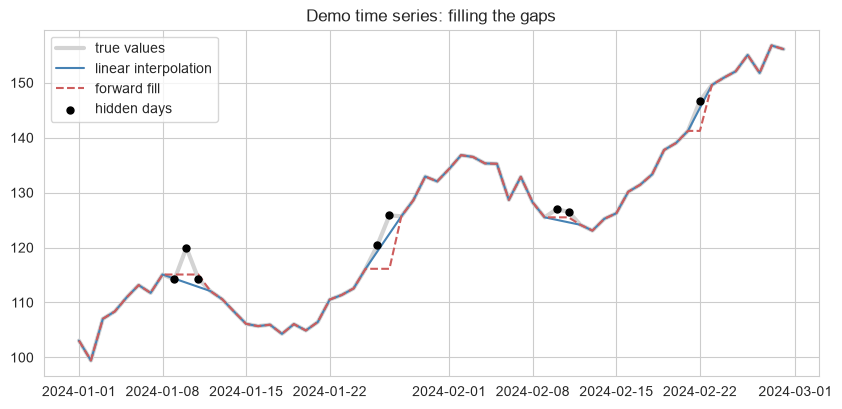

In [14]:
# 1) on the UNORDERED Telco rows
fill_value = observed.median()                      # for the first / last rows that have no neighbour
evaluate("forward fill (unordered)", observed.ffill().fillna(fill_value))
evaluate("backward fill (unordered)", observed.bfill().fillna(fill_value))
evaluate("interpolate (unordered)", observed.interpolate().fillna(fill_value))
print(pd.DataFrame(results).T.loc[["mean", "median", "forward fill (unordered)", "backward fill (unordered)", "interpolate (unordered)"]])

# 2) on a DEMO time series (made by me): daily sales for 60 days
days = pd.date_range("2024-01-01", periods=60, freq="D")
rng3 = np.random.default_rng(3)
t = np.arange(60)
sales_true = pd.Series(100 + 0.8 * t + 10 * np.sin(t / 4) + rng3.normal(0, 1.5, 60), index=days)

gap_positions = [8, 9, 10, 25, 26, 40, 41, 52]
sales = sales_true.copy()
sales.iloc[gap_positions] = np.nan

ts_methods = {
    "mean": sales.fillna(sales.mean()),
    "forward fill": sales.ffill(),
    "backward fill": sales.bfill(),
    "linear interpolation": sales.interpolate(method="linear"),
}
ts_rmse = {k: round(float(np.sqrt(((v.iloc[gap_positions] - sales_true.iloc[gap_positions]) ** 2).mean())), 2) for k, v in ts_methods.items()}
print("\nTIME SERIES: RMSE at the hidden days")
print(ts_rmse)

plt.figure(figsize=(10, 4.5))
plt.plot(sales_true.index, sales_true, color="lightgray", linewidth=3, label="true values")
plt.plot(ts_methods["linear interpolation"].index, ts_methods["linear interpolation"], color="steelblue", label="linear interpolation")
plt.plot(ts_methods["forward fill"].index, ts_methods["forward fill"], color="indianred", linestyle="--", label="forward fill")
plt.scatter(sales.index[gap_positions], sales_true.iloc[gap_positions], color="black", s=25, zorder=3, label="hidden days")
plt.title("Demo time series: filling the gaps")
plt.legend()
plt.show()

**What the code does:**
- Part 1: it applies `ffill()`, `bfill()` and `interpolate()` to the Telco `TotalCharges` with holes. The rows are in a random order, so each value is copied from or mixed with a different customer. If the first or the last row is empty (there is no neighbour), it is filled with the median.
- Part 2: it creates a demo series of daily sales with a trend, a wave and some noise, and hides 8 days (three gaps of 3, 2 and 2 days, and a single one). It fills the gaps with the mean, `ffill`, `bfill` and linear interpolation, and calculates the RMSE only for the hidden days.
- It draws the true values, the interpolation and the forward fill together, and marks the hidden days.

**Why this method was used:** The same three methods have to be tested twice to show that the question is not "which method is better" but "does the data have an order". If the method is right for the data, it is very good (time series). If it is applied to unordered rows, it is almost the same as a random guess. I used `interpolate(method="linear")` because the demo series changes smoothly, and a straight line between two neighbours is a good estimate. For the Telco rows, the same methods show what happens when they are used on the wrong kind of data.

**Output meaning:** On the Telco rows the three methods have a large error, similar to or worse than the mean and the median, because the neighbour of a row is another unrelated customer. On the time series the linear interpolation has by far the smallest error, forward fill and backward fill follow the data but make steps, and the mean is the worst. The chart shows the interpolation line passing very close to the hidden days, while forward fill stays flat in every gap.

**Effect on ML:** These methods are for time series and ordered data only. In the churn data they must not be used, and for time series the use of `bfill` and interpolation needs care, because they use future values, and this can cause temporal leakage if the data is used for forecasting (Notebook 13).

## 9. Group-Based Imputation

**Concept:** The missing value is replaced with a statistic of a group of similar rows (the median of the same contract, the mode of the same city, and so on). It uses other columns, so the filled value is closer to the real one than one number for the whole column.

- **When to use:** the missing value depends on a categorical column (MAR), and every group has enough rows.
- **When not to use:** the groups are small, the grouping column is not related to the missing column, or the grouping column also has missing values.
- **Advantages:** simple, easy to explain to the business, keeps the differences between groups.
- **Limitations:** I must choose the groups, small groups give unstable values, and the spread inside a group is still lost.

**Examples:**
- Simple: fill a missing height with the average height of the same gender.
- Real-world: fill a missing salary with the median salary of the same job.
- Business: fill a missing total with the median of customers with a similar tenure.
- AI/ML: a good middle step between a single value and a model-based imputation.

**Implementation:** I group the customers by tenure band and internet service, and I fill the holes with the median of the group.

In [15]:
exp["tenure_group"] = pd.cut(exp["tenure"], bins=[0, 6, 12, 24, 36, 48, 60, 72])

group_median = exp.groupby(["tenure_group", "InternetService"], observed=True)["TotalCharges"].transform("median")
imputed_group = exp["TotalCharges"].fillna(group_median).fillna(observed.median())   # safety net for empty groups
evaluate("group median (tenure band + service)", imputed_group)

print("Number of groups:", exp.groupby(["tenure_group", "InternetService"], observed=True).ngroups)
print("Smallest group size:", int(exp.groupby(["tenure_group", "InternetService"], observed=True).size().min()))
print()
print(pd.DataFrame(results).T.loc[["mean", "median", "group median (tenure band + service)"]])

Number of groups: 21
Smallest group size: 161

                                        RMSE     std  corr_with_tenure
mean                                  2296.7  2089.2             0.763
median                                2472.6  2112.3             0.754
group median (tenure band + service)   543.6  2258.3             0.828


**What the code does:**
- It divides `tenure` into 7 bands with `pd.cut`, so customers with a similar tenure are together.
- `groupby([...]).transform("median")` calculates the median of the observed `TotalCharges` inside every group (tenure band and internet service), and returns a column of the same length, where each row has the median of its own group.
- `fillna` takes this group median only where the value is missing. A second `fillna` with the global median is a safety net for the case that a group has no observed value.
- It prints how many groups exist and how big the smallest group is, then compares the result with the mean and the median.

**Why this method was used:** `TotalCharges` is mainly the number of months multiplied by the monthly price, so tenure and internet service (which decides the price level) are exactly the columns that explain it. `transform` is better than a loop, because it keeps the original index and fills everything in one step. I check the size of the smallest group, because a group with only one or two customers gives an unreliable median.

**Output meaning:** The error is much lower than with the mean or the median, and the correlation with tenure is almost the real one, because a new customer gets a small value and a long-term customer gets a large value.

**Effect on ML:** Group-based imputation keeps the relation between the columns, which a single value destroys. The groups must be chosen with a business reason, and in a real pipeline the group statistics must be learned from the training data only.

## 10. KNN Imputation

**Concept:** For a row with a missing value, KNN imputation finds the K most similar rows (nearest neighbours) using the other columns, and fills the hole with the average of their values. Because it measures distances, the columns must be scaled first.

- **When to use:** numeric columns that are related to each other, a missing share up to about 20-30%, a dataset that is not too big.
- **When not to use:** very large datasets (it is slow), columns with many irrelevant features, unscaled data.
- **Advantages:** uses the relations between columns, and the values come from real similar rows.
- **Limitations:** slow on big data, sensitive to scaling and to the choice of K, and it needs numeric columns.

**Examples:**
- Simple: a missing age is guessed from the 5 people with the most similar answers.
- Real-world: a recommendation of a missing rating from similar users.
- Business: a missing total charge from customers with similar tenure and monthly charge.
- AI/ML: `KNNImputer` in scikit-learn.

**Implementation:** I use the three numeric columns, scale them, impute with K=5, and scale back.

In [16]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

numeric = exp[["tenure", "MonthlyCharges", "TotalCharges"]]

scaler = StandardScaler()
scaled = scaler.fit_transform(numeric)                  # the scaler ignores NaN when learning mean and std

knn = KNNImputer(n_neighbors=5)
filled_scaled = knn.fit_transform(scaled)
filled = scaler.inverse_transform(filled_scaled)

imputed_knn = pd.Series(filled[:, 2], index=exp.index)
evaluate("KNN (k=5)", imputed_knn)
print(pd.DataFrame(results).T.loc[["mean", "median", "group median (tenure band + service)", "KNN (k=5)"]])

                                        RMSE     std  corr_with_tenure
mean                                  2296.7  2089.2             0.763
median                                2472.6  2112.3             0.754
group median (tenure band + service)   543.6  2258.3             0.828
KNN (k=5)                               77.3  2266.6             0.826


**What the code does:**
- It takes the three numeric columns (the one with holes and two helpers: tenure and monthly charges).
- `StandardScaler` puts the columns on the same scale. It skips the `NaN` values when it calculates the mean and the standard deviation.
- `KNNImputer(n_neighbors=5)` finds for each row with a hole the 5 closest rows (using the columns that are not missing) and fills the hole with the average of their `TotalCharges`.
- `inverse_transform` returns the values to the original scale, and the third column is the imputed `TotalCharges`, which is evaluated.

**Why this method was used:** KNN works with distances, and tenure (0 to 72), monthly charges (18 to 119) and total charges (up to 8000) have very different sizes, so without scaling the large column would decide the neighbours alone. I picked K=5 as a common starting value: a very small K is noisy and a very large K gives something close to the mean. I used only numeric helper columns because KNNImputer needs numbers.

**Output meaning:** The error is one of the smallest in the table, and the std and the correlation with tenure are close to the true values. The neighbours of a customer with a long tenure and a high monthly charge are customers who paid a large total.

**Effect on ML:** KNN gives realistic values and keeps the shape of the column. The cost is speed and the need to fit it on the training data only (in a pipeline it is a step that is fitted on `X_train` and applied to `X_test`).

## 11. Iterative Imputation

**Concept:** Iterative imputation (also called MICE style) treats each column with missing values as a target of a regression model that uses all the other columns. It repeats the process several times, and each round improves the filled values.

- **When to use:** numeric columns with relations between them, MAR data, and when accuracy is more important than speed.
- **When not to use:** very large data, a few weak relations between columns, or when the result must be easy to explain.
- **Advantages:** uses all the other columns, usually the most accurate of the statistical methods.
- **Limitations:** slower, harder to explain, can fail to converge, and it is still experimental in scikit-learn.

**Examples:**
- Simple: predict the missing weight from height and age.
- Real-world: fill the missing values of a medical test from the other tests.
- Business: estimate a missing total from tenure and monthly charge.
- AI/ML: `IterativeImputer` in scikit-learn.

**Implementation:**

In [17]:
from sklearn.experimental import enable_iterative_imputer      # needed because the class is still experimental
from sklearn.impute import IterativeImputer

iterative = IterativeImputer(max_iter=10, random_state=0)
filled_iter = iterative.fit_transform(numeric)

imputed_iter = pd.Series(filled_iter[:, 2], index=exp.index)
evaluate("iterative", imputed_iter)

print("Iterations used:", iterative.n_iter_)
print(pd.DataFrame(results).T.loc[["mean", "median", "group median (tenure band + service)", "KNN (k=5)", "iterative"]])

Iterations used: 2
                                        RMSE     std  corr_with_tenure
mean                                  2296.7  2089.2             0.763
median                                2472.6  2112.3             0.754
group median (tenure band + service)   543.6  2258.3             0.828
KNN (k=5)                               77.3  2266.6             0.826
iterative                              745.4  2244.2             0.833


**What the code does:**
- The line `enable_iterative_imputer` is required, because the class is marked as experimental in scikit-learn.
- `IterativeImputer(max_iter=10, random_state=0)` builds a regression model (by default `BayesianRidge`) that predicts `TotalCharges` from `tenure` and `MonthlyCharges`, fills the holes with the predictions, and repeats up to 10 rounds. `random_state` makes the result repeatable.
- It prints the number of rounds that were used, and the evaluation.

**Why this method was used:** `TotalCharges` depends on tenure and monthly charge, so a regression that uses the other columns is a natural choice. A regression uses the relation between columns in a smooth way, while KNN only copies from the neighbours. I did not scale the data here, because the regression is not based on distances.

**Output meaning:** The error is much lower than with the mean or the median, and the correlation with tenure is close to the real one. It is not better than KNN here, because the default model is a straight line, and `TotalCharges` is closer to a product (tenure x monthly charge) than to a straight-line relation.

**Effect on ML:** More complex does not always mean better. Iterative imputation adds a hidden model to the pipeline and makes it harder to explain, so I use it only when a simpler technique is clearly worse.

## 12. Comparison of All Techniques

                                        RMSE     std  corr_with_tenure
KNN (k=5)                               77.3  2266.6             0.826
group median (tenure band + service)   543.6  2258.3             0.828
iterative                              745.4  2244.2             0.833
mean                                  2296.7  2089.2             0.763
median                                2472.6  2112.3             0.754
interpolate (unordered)               2818.4  2180.6             0.727
forward fill (unordered)              3189.3  2257.2             0.703
backward fill (unordered)             3250.7  2266.1             0.700
constant 0                            3260.3  2239.2             0.709
TRUE VALUES                              0.0  2266.8             0.826


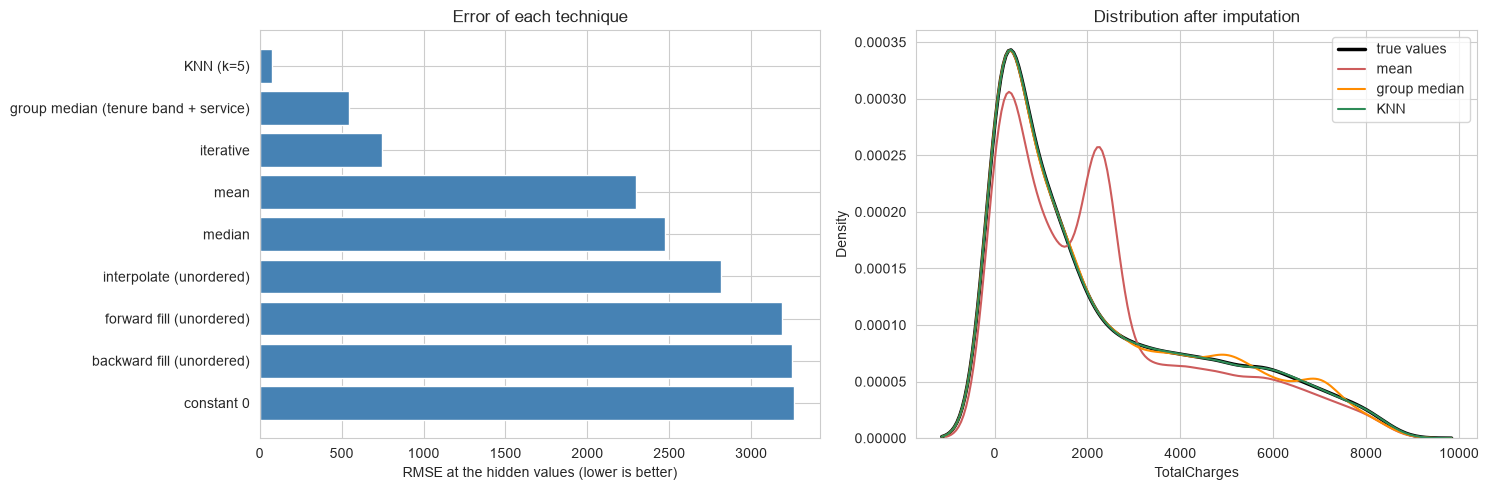

In [18]:
comparison = pd.DataFrame(results).T.sort_values("RMSE")
comparison.loc["TRUE VALUES"] = [0.0, round(truth.std(), 1), round(truth.corr(base["tenure"]), 3)]
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_data = comparison.drop("TRUE VALUES")["RMSE"].sort_values()
axes[0].barh(plot_data.index, plot_data.values, color="steelblue")
axes[0].invert_yaxis()
axes[0].set_xlabel("RMSE at the hidden values (lower is better)")
axes[0].set_title("Error of each technique")

sns.kdeplot(truth, ax=axes[1], color="black", linewidth=2.5, label="true values")
sns.kdeplot(imputed_mean, ax=axes[1], color="indianred", label="mean")
sns.kdeplot(imputed_group, ax=axes[1], color="darkorange", label="group median")
sns.kdeplot(imputed_knn, ax=axes[1], color="seagreen", label="KNN")
axes[1].set_title("Distribution after imputation")
axes[1].set_xlabel("TotalCharges")
axes[1].legend()
plt.tight_layout()
plt.show()

**What the code does:**
- It puts the results of all techniques in one table, sorted by the error, and adds a row with the true values as a reference for std and correlation.
- The left chart is a bar chart of the RMSE of each technique.
- The right chart compares the density of the true values with the density after mean, group median and KNN imputation.

**Why this method was used:** A table gives exact numbers and the charts show the shape. The bar chart answers "which is closer", and the density chart answers "does the column keep its shape", which the RMSE alone cannot say. I show the mean, the group median and KNN in the density chart, because they represent three different ideas: one value for all, one value per group, and a value from similar rows.

**Output meaning:**
- The techniques that use other columns (iterative, KNN, group median) have a much lower error than the ones that use one value (mean, median, constant).
- The constant 0 is the worst, and forward fill, backward fill and interpolation on unordered rows are close to the mean or worse, because the neighbour has no meaning.
- Mean imputation makes a sharp peak in the density chart, and the std is smaller than the true std. KNN and the group median keep a shape that is close to the true one.

**Insight obtained:** There is no best technique for everything. The best choice depends on the mechanism (MCAR, MAR, MNAR), the type of column, the order of rows, the size of the data and the need to explain the result. Filling everything with the mean is the simplest choice, but here it is one of the worst.

**Effect on ML:** Methods that use the relation between columns give the model realistic data. The simple methods are acceptable only for a very small missing share, or as a safety net in a pipeline.

## 13. Decision for the Real Missing Values (TotalCharges)

The recovery experiment is about random missing values, but the real 11 values are not random, they are structural: the customer is new and has not paid anything. So I compare the options with this special knowledge.

In [19]:
real_missing = df_clean[df_clean["TotalCharges"].isna()][["tenure", "MonthlyCharges"]].copy()
observed_real = df_clean["TotalCharges"].dropna()

options = {
    "constant 0 (business rule)": 0.0,
    "median of all customers": observed_real.median(),
    "mean of all customers": observed_real.mean(),
}

rows = []
for name, value in options.items():
    months_paid = value / real_missing["MonthlyCharges"]            # how many monthly bills this total means
    rows.append((name, round(value, 1), round(months_paid.mean(), 1)))

check = pd.DataFrame(rows, columns=["option", "value_filled", "implied_months_of_bills"])
print("Tenure of these 11 customers:", real_missing["tenure"].unique().tolist(), "months")
print()
print(check)
print("\nOption 'drop rows': removes", len(real_missing), "customers, all of them with tenure 0")

Tenure of these 11 customers: [0] months

                       option  value_filled  implied_months_of_bills
0  constant 0 (business rule)           0.0                      0.0
1     median of all customers        1397.5                     45.5
2       mean of all customers        2283.3                     74.3

Option 'drop rows': removes 11 customers, all of them with tenure 0


**What the code does:**
- It selects the 11 customers with a missing `TotalCharges`, and calculates the median and the mean of all the known values.
- For each option (0, median, mean) it calculates how many monthly bills the filled total means for these customers, by dividing the filled value by their own monthly charge.
- It prints the tenure of these customers, the table of options, and the number of customers that would be removed by dropping.

**Why this method was used:** Instead of choosing a technique by habit, I test each option against a fact that I know: these customers have tenure 0, so the number of bills they have paid must be 0. The "implied months of bills" turns the filled value into a number that can be compared with the tenure. This gives a business argument that is easy to explain in the review.

**Output meaning:** With 0 the implied number of bills is 0, which is the same as the tenure. With the median or the mean it is more than a year of bills for a customer who joined this month, which is not possible. Dropping the rows removes the only customers with tenure 0.

**Decision:** I fill these values with the constant **0**, and I keep the rows.

| Option | Decision | Reason |
|---|---|---|
| Drop rows | rejected | removes all new customers, and the missing is not random |
| Mean / median | rejected | gives a bill of more than a year to a customer who has not paid yet |
| KNN / iterative | rejected | gives a prediction for a value that is not unknown, it is zero by definition |
| Constant 0 | **selected** | follows the business meaning, and it is a fixed rule |

**Effect on ML:** The rule uses no statistics of the data, so it cannot leak information from the test set, and it can be applied before the train/test split. The model keeps the new customers and sees the correct relation between tenure and total charges at the start of the customer life. If I later use `SimpleImputer(strategy="median")` in the pipeline of Notebook 14, it is only a safety net for new data, and it will not change these rows.

In [20]:
def handle_missing_values(data):
    out = data.copy()                                       # raw data is never changed
    new_customer = out["tenure"] == 0
    out.loc[new_customer, "TotalCharges"] = out.loc[new_customer, "TotalCharges"].fillna(0.0)
    return out

df_filled = handle_missing_values(df_clean)

# validation
assert df_filled.isna().sum().sum() == 0, "there are still missing values"
assert len(df_filled) == len(df_clean), "rows were lost"

summary = pd.DataFrame({
    "before": [len(df_clean), int(df_clean.isna().sum().sum()), round(df_clean["TotalCharges"].mean(), 2),
               round(df_clean["TotalCharges"].median(), 2), round(df_clean["TotalCharges"].min(), 2), int((df_clean["tenure"] == 0).sum())],
    "after":  [len(df_filled), int(df_filled.isna().sum().sum()), round(df_filled["TotalCharges"].mean(), 2),
               round(df_filled["TotalCharges"].median(), 2), round(df_filled["TotalCharges"].min(), 2), int((df_filled["tenure"] == 0).sum())],
}, index=["rows", "missing values", "TotalCharges mean", "TotalCharges median", "TotalCharges min", "customers with tenure 0"])
print(summary)

print("\nRaw data untouched, TotalCharges dtype:", df["TotalCharges"].dtype)

                          before    after
rows                     7043.00  7043.00
missing values             11.00     0.00
TotalCharges mean        2283.30  2279.73
TotalCharges median      1397.48  1394.55
TotalCharges min           18.80     0.00
customers with tenure 0    11.00    11.00

Raw data untouched, TotalCharges dtype: str


**What the code does:**
- The function `handle_missing_values` copies the data, selects the customers with tenure 0, and fills only their missing `TotalCharges` with 0. Other rows are not touched.
- Two `assert` statements stop the code if a missing value is left, or if the number of rows changed.
- A before/after table shows rows, missing values and the main statistics of `TotalCharges`.

**Why this method was used:** The condition `tenure == 0` makes the rule explicit, so the code says what the business rule is. If a missing `TotalCharges` appears for a customer with tenure above 0 (a real error), it is not silently filled, and the `assert` stops the process so that I can look at it. A function can be used again in the final workflow, and `assert` is a cheap validation that protects the pipeline.

**Before:** 11 missing values, the minimum of `TotalCharges` is above 0.

**After:** No missing values, the same number of rows, the minimum is 0, and the mean and median are slightly lower because 11 zeros were added.

**Effect on ML:** The dataset is complete, and the new customers stay in the data with the correct value.

In [21]:
df_filled.to_csv("telco_step3_missing_handled.csv", index=False)

if os.path.exists("data_quality_issue_log.csv"):
    log = pd.read_csv("data_quality_issue_log.csv")
    log.loc[log["id"] == 2, "status"] = "done (Notebook 3)"
    log.to_csv("data_quality_issue_log.csv", index=False)
    print(log[["id", "column", "problem", "status"]].head(3))
else:
    print("data_quality_issue_log.csv not found (run Notebook 1 first)")

   id        column                   problem             status
0   1  TotalCharges            stored as text  done (Notebook 2)
1   2  TotalCharges  11 hidden missing values  done (Notebook 3)
2   3      all rows           duplicate check           verified


**What the code does:** It saves the dataset without missing values, and changes the status of issue 2 (the 11 hidden missing values) to done in the issue log.

**Why this method was used:** A saved file and an updated log keep the sprint connected. The CSV does not store dtypes, so later notebooks load the raw CSV and call `fix_data_types` and `handle_missing_values` again.

## 14. Documentation of the Decision

| Item | Documentation |
|---|---|
| Problem | 11 customers have a missing `TotalCharges` (hidden as blank spaces, made visible in Notebook 2) |
| Analysis | All of them have `tenure = 0`, and all customers with tenure 0 are in the group, so the missing is explained by another column (MAR) and it is structural: the first bill does not exist yet |
| Technique selected | Constant imputation with 0, only for customers with `tenure == 0` |
| Reason | Dropping removes all new customers, the mean and the median give more than a year of bills to a new customer, and KNN or iterative imputation would predict a value that is known to be 0 |
| Implementation | `handle_missing_values()` in Section 13, with an `assert` that no missing value is left |
| Result | 0 missing values, 7043 rows, the minimum of `TotalCharges` is 0 |
| Impact | The model keeps the new customers and can learn from the start of the customer life. The rule is fixed, so it causes no leakage |

# Summary of Techniques

| Technique | Use when | Avoid when |
|---|---|---|
| Drop rows | tiny MCAR share, or the target is missing | MAR or MNAR, small data |
| Drop columns | above about 50% missing and not important | the column is important or the missing has a meaning |
| Mean | symmetric numeric data, small MCAR share | skewed data, outliers |
| Median | skewed numeric data | the relation with other columns matters |
| Mode | categorical, one dominant label | similar label frequencies, large share |
| Constant | the missing has a meaning or a business rule | random missing in numeric data |
| Forward / backward fill | ordered data (time) | unordered rows, forecasting with future values |
| Interpolation | smooth ordered numeric data | unordered or categorical data |
| Group-based | the value depends on a category (MAR) | small groups, unrelated groups |
| KNN | related numeric columns, medium data | large data, unscaled data |
| Iterative | related numeric columns, accuracy needed | large data, need for a simple explanation |

**Key findings on the Telco data:**
- Only 11 values are missing (`TotalCharges`, 0.16%), and they were hidden as blank spaces.
- The missing is structural (tenure 0), so the correct value is 0, and the mean, the median or dropping would all be wrong.
- In the recovery experiment, methods that use other columns (group, KNN, iterative) are much better than one value for the whole column. The mean makes a peak and reduces the variance.
- ffill, bfill and interpolation only work when the rows have an order.
- Statistics-based imputers (median, KNN, iterative) must be fitted on the training data only.

**What I learned:** The percentage of missing values is not enough to choose a technique. I must first understand why the values are missing, then test the options against something that I know. A method that is easy to use, like the mean, can be one of the worst.

**Next:** Notebook 4 - Duplicate Data Handling.